# Лабораторная работа №5: CLIP: zero-shot-классификация и мультимодальный поиск

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Сравнить prompt templates в zero-shot classification.
- Построить text-to-image retrieval.
- Дообучить projection head и оценить Recall@K.


## Теоретическая часть

CLIP обучает image encoder и text encoder в общем нормированном пространстве. Zero-shot logits пропорциональны cosine similarity между изображением и текстовыми шаблонами классов.

![CLIP](https://raw.githubusercontent.com/openai/CLIP/main/CLIP.png)


### Математическая постановка

$$s(x,t)=\frac{f_I(x)^\top f_T(t)}{\|f_I(x)\|\|f_T(t)\|},\qquad p(c\mid x)=\operatorname{softmax}(s(x,t_c)/\tau).$$
Для retrieval используются Recall@K и median rank.


### Материалы

- [OpenCLIP](https://github.com/mlfoundations/open_clip)
- [CLIP paper](https://arxiv.org/abs/2103.00020)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Сравнить prompt templates в zero-shot classification.
2. Построить text-to-image retrieval.
3. Дообучить projection head и оценить Recall@K.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** OpenCLIP ViT-B-32 frozen/малый projection head.
- **Ограничение данных:** CIFAR-10 или до 5 000 пар.
- **Fallback:** CPU на 500 объектах.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 20
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
DATA_ROOT = Path.cwd() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cpu', 'fast_dev_run': False, 'data_root': 'c:\\Anton\\16 триместр\\SOTA\\lab5\\data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

In [3]:
# Библиотеки

from torch.utils.data import Dataset, DataLoader, Subset, TensorDataset
from torchvision.datasets import CIFAR10
import open_clip
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math

import torch.nn as nn

c:\Anton\16 триместр\movenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Данные и предобученный CLIP

*Вес: 1 балл.*

**Постановка.** Индекс поиска и обучающие пары должны состоять из разных изображений.

Выполните следующие действия:
1. Загрузите CIFAR-10 train/test и OpenCLIP ViT-B-32.
2. Определите список классов и независимый test-загрузчик.

**Результат.** Объекты model, train_pairs, ds, classes, loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
# --------------------------------------------------
# 1. Параметры эксперимента
# --------------------------------------------------

if FAST_DEV_RUN:
    N_TRAIN = 64
    N_VAL = 16
    N_TEST = 32
    BATCH_SIZE = 8
else:
    N_TRAIN = 20_000
    N_VAL = 3_000
    N_TEST = 10_000
    BATCH_SIZE = 32

NUM_WORKERS = 0  # Надёжнее для CPU и Jupyter Notebook

# --------------------------------------------------
# 2. Загружаем CIFAR-10
# --------------------------------------------------

cifar_root = DATA_ROOT / "cifar10"
cifar_root.mkdir(parents=True, exist_ok=True)

# Оставляем изображения в формате PIL:
# преобразования выполнит preprocess от OpenCLIP.
cifar_train = CIFAR10(
    root=str(cifar_root),
    train=True,
    download=True,
    transform=None,
)

cifar_test = CIFAR10(
    root=str(cifar_root),
    train=False,
    download=True,
    transform=None,
)

classes = list(cifar_train.classes)

assert classes == list(cifar_test.classes)
assert N_TRAIN + N_VAL <= len(cifar_train)
assert N_TEST <= len(cifar_test)

# --------------------------------------------------
# 3. Загружаем предобученный OpenCLIP ViT-B-32
# --------------------------------------------------

MODEL_NAME = "ViT-B-32"
PRETRAINED = "laion2b_s34b_b79k"

model, preprocess_train, preprocess_val = (
    open_clip.create_model_and_transforms(
        MODEL_NAME,
        pretrained=PRETRAINED,
        device=DEVICE,
    )
)

tokenizer = open_clip.get_tokenizer(MODEL_NAME)

model.eval()

# На данном этапе модель не обучаем.
for parameter in model.parameters():
    parameter.requires_grad = False

# --------------------------------------------------
# 4. Dataset для пар «изображение — текст»
# --------------------------------------------------

class CIFARTextPairs(Dataset):
    """Возвращает изображение, текстовую подпись и метку класса."""

    def __init__(self, base_dataset, indices, transform, class_names):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform
        self.class_names = class_names

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image_index = self.indices[index]
        image, label = self.base_dataset[image_index]

        if self.transform is not None:
            image = self.transform(image)

        caption = f"a photo of a {self.class_names[label]}"

        return image, caption, label


class CIFARImages(Dataset):
    """Возвращает изображение и метку для независимой оценки."""

    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image_index = self.indices[index]
        image, label = self.base_dataset[image_index]

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# --------------------------------------------------
# 5. Создаём непересекающиеся выборки
# --------------------------------------------------

generator = torch.Generator().manual_seed(SEED)

# Перемешиваем только индексы исходного train-набора.
train_indices = torch.randperm(
    len(cifar_train), generator=generator
).tolist()

fit_indices = train_indices[:N_TRAIN]
val_indices = train_indices[N_TRAIN:N_TRAIN + N_VAL]

# Тестовые индексы берутся из отдельного CIFAR-10 test.
test_indices = torch.randperm(
    len(cifar_test), generator=generator
)[:N_TEST].tolist()

train_pairs = CIFARTextPairs(
    base_dataset=cifar_train,
    indices=fit_indices,
    transform=preprocess_train,
    class_names=classes,
)

val_pairs = CIFARTextPairs(
    base_dataset=cifar_train,
    indices=val_indices,
    transform=preprocess_val,
    class_names=classes,
)

# ds — независимый набор изображений для тестирования и поиска.
ds = CIFARImages(
    base_dataset=cifar_test,
    indices=test_indices,
    transform=preprocess_val,
)

# loader — загрузчик независимой тестовой выборки.
loader = DataLoader(
    ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE == "cuda"),
)

# Отдельный загрузчик валидационных пар.
val_loader = DataLoader(
    val_pairs,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE == "cuda"),
)

# --------------------------------------------------
# 6. Проверяем результат
# --------------------------------------------------

assert len(train_pairs) == N_TRAIN
assert len(val_pairs) == N_VAL
assert len(ds) == N_TEST
assert set(fit_indices).isdisjoint(val_indices)

print("Модель и данные подготовлены.")
print(f"Устройство: {DEVICE}")
print(f"Модель: {MODEL_NAME} ({PRETRAINED})")
print(f"Классы ({len(classes)}): {classes}")
print(f"Обучающие пары: {len(train_pairs)}")
print(f"Валидационные пары: {len(val_pairs)}")
print(f"Тестовые изображения: {len(ds)}")
print(f"Батчей в тестовом loader: {len(loader)}")
print(f"FAST_DEV_RUN: {FAST_DEV_RUN}")

# Пример одной обучающей пары.
sample_image, sample_caption, sample_label = train_pairs[0]
print("Пример подписи:", sample_caption)
print("Метка класса:", sample_label)
print("Размер изображения после preprocessing:", sample_image.shape)

Модель и данные подготовлены.
Устройство: cpu
Модель: ViT-B-32 (laion2b_s34b_b79k)
Классы (10): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Обучающие пары: 20000
Валидационные пары: 3000
Тестовые изображения: 10000
Батчей в тестовом loader: 313
FAST_DEV_RUN: False
Пример подписи: a photo of a truck
Метка класса: 9
Размер изображения после preprocessing: torch.Size([3, 224, 224])


### Текстовые прототипы классов

*Вес: 1 балл.*

**Постановка.** Нормализация эмбеддингов превращает скалярное произведение в cosine similarity.

Выполните следующие действия:
1. Создайте несколько шаблонов класса.
2. Закодируйте и нормируйте текстовые прототипы.

**Результат.** templates и функция text_prototypes.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
# Несколько шаблонов для сравнения в zero-shot классификации.
# {class} будет заменяться названием каждого класса.
templates = [
    "{class}",
    "a photo of a {class}",
    "a picture of a {class}",
    "an image of a {class}",
    "это фотография {class}",
]

def text_prototypes(model, tokenizer, classes, templates, device=DEVICE):
    """
    Создаёт нормализованные текстовые прототипы классов.

    Возвращает:
        prototypes: тензор [num_templates, num_classes, embedding_dim]
    """
    if not classes:
        raise ValueError("Список classes не должен быть пустым.")
    if not templates:
        raise ValueError("Список templates не должен быть пустым.")

    model.eval()
    all_prototypes = []

    with torch.no_grad():
        for template in templates:
            # Создаём текст для каждого класса.
            texts = [
                template.format(**{"class": class_name})
                for class_name in classes
            ]

            # Преобразуем тексты в токены.
            tokens = tokenizer(texts).to(device)

            # Получаем текстовые эмбеддинги CLIP.
            features = model.encode_text(tokens)

            # Переводим в float32 и нормализуем каждый вектор.
            features = F.normalize(features.float(), p=2, dim=-1)

            all_prototypes.append(features)

    # [num_templates, num_classes, embedding_dim]
    prototypes = torch.stack(all_prototypes, dim=0)

    return prototypes


# Создаём прототипы классов.
text_features = text_prototypes(
    model=model,
    tokenizer=tokenizer,
    classes=classes,
    templates=templates,
    device=DEVICE,
)

# Проверяем форму результата и нормализацию.
assert text_features.shape[0] == len(templates)
assert text_features.shape[1] == len(classes)
assert torch.allclose(
    text_features.norm(dim=-1),
    torch.ones_like(text_features.norm(dim=-1)),
    atol=1e-5,
)

print("Шаблоны:", templates)
print("Количество классов:", len(classes))
print("Размер текстовых прототипов:", tuple(text_features.shape))
print("Средняя норма эмбеддингов:", text_features.norm(dim=-1).mean().item())

Шаблоны: ['{class}', 'a photo of a {class}', 'a picture of a {class}', 'an image of a {class}', 'это фотография {class}']
Количество классов: 10
Размер текстовых прототипов: (5, 10, 512)
Средняя норма эмбеддингов: 1.0


### Zero-shot классификация

*Вес: 1 балл.*

**Постановка.** Подбор словесного шаблона влияет на прогноз без дополнительного обучения.

Выполните следующие действия:
1. Для каждого заранее заданного шаблона предскажите test-классы по сходству.
2. Зафиксируйте accuracy всех шаблонов без выбора лучшей модели по test.

**Результат.** zero_shot.json с фактической точностью шаблонов.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
# Проверяем, что предыдущие ячейки выполнены.
assert "model" in globals()
assert "classes" in globals()
assert "templates" in globals()
assert "text_prototypes" in globals()
assert "loader" in globals()

model.eval()

# Получаем нормализованные текстовые прототипы:
# [num_templates, num_classes, embedding_dim]
prototypes = text_prototypes(
    model=model,
    tokenizer=tokenizer,
    classes=classes,
    templates=templates,
    device=DEVICE,
)

results = []

# Оцениваем каждый шаблон на одном и том же тестовом наборе.
with torch.inference_mode():
    for template_idx, template in enumerate(templates):
        class_prototypes = prototypes[template_idx].to(DEVICE)

        correct = 0
        total = 0

        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            # Кодируем изображения.
            image_features = model.encode_image(images).float()

            # Нормируем эмбеддинги изображений.
            image_features = F.normalize(
                image_features, p=2, dim=-1
            )

            # Сходство изображения с каждым классом.
            # Векторы изображения и текста уже нормализованы,
            # поэтому скалярное произведение равно cosine similarity.
            similarities = image_features @ class_prototypes.T

            # Выбираем класс с максимальным сходством.
            predictions = similarities.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.numel()

        accuracy = correct / total if total > 0 else 0.0

        results.append({
            "template": template,
            "accuracy": accuracy,
            "correct": correct,
            "total": total,
        })

        print(
            f"Template: {template!r} | "
            f"Accuracy: {accuracy:.4f} "
            f"({correct}/{total})"
        )

# Сохраняем результаты всех шаблонов, не выбирая лучший.
report = {
    "model": MODEL_NAME,
    "pretrained": PRETRAINED,
    "dataset": "CIFAR-10",
    "split": "test",
    "fast_dev_run": FAST_DEV_RUN,
    "num_test_images": len(ds),
    "classes": classes,
    "results": results,
}

output_path = ARTIFACTS / "zero_shot.json"

with output_path.open("w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

print(f"\nРезультаты сохранены: {output_path.resolve()}")
print(f"Число оценённых шаблонов: {len(results)}")
print(f"Число тестовых изображений: {len(ds)}")

Template: '{class}' | Accuracy: 0.7175 (7175/10000)
Template: 'a photo of a {class}' | Accuracy: 0.9366 (9366/10000)
Template: 'a picture of a {class}' | Accuracy: 0.9362 (9362/10000)
Template: 'an image of a {class}' | Accuracy: 0.9361 (9361/10000)
Template: 'это фотография {class}' | Accuracy: 0.9355 (9355/10000)

Результаты сохранены: C:\Anton\16 триместр\SOTA\lab5\artifacts\zero_shot.json
Число оценённых шаблонов: 5
Число тестовых изображений: 10000


### Векторный индекс изображений

*Вес: 1 балл.*

**Постановка.** Текстовый поиск опирается на сохранённые признаки реальных изображений.

Выполните следующие действия:
1. Извлеките нормированные эмбеддинги test и метки.
2. Вычислите top-10 для текстового запроса.

**Результат.** clip_index.pt и retrieval.json с индексами test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
# --------------------------------------------------
# 1. Извлекаем эмбеддинги тестовых изображений
# --------------------------------------------------

model.eval()

image_embeddings = []
image_labels = []

with torch.inference_mode():
    for images, labels in loader:
        images = images.to(DEVICE)

        # Получаем визуальные признаки CLIP.
        features = model.encode_image(images).float()

        # Нормализация превращает скалярное произведение
        # эмбеддингов в cosine similarity.
        features = F.normalize(features, p=2, dim=-1)

        image_embeddings.append(features.cpu())
        image_labels.append(labels.cpu())

# Объединяем все батчи.
image_embeddings = torch.cat(image_embeddings, dim=0)
image_labels = torch.cat(image_labels, dim=0)

# Индексы объектов в исходном CIFAR-10 test.
test_indices = torch.tensor(ds.indices, dtype=torch.long)

assert len(image_embeddings) == len(ds)
assert len(image_labels) == len(ds)
assert len(test_indices) == len(ds)

# --------------------------------------------------
# 2. Сохраняем векторный индекс
# --------------------------------------------------

index_data = {
    "embeddings": image_embeddings,
    "labels": image_labels,
    "test_indices": test_indices,
    "classes": classes,
    "model_name": MODEL_NAME,
    "pretrained": PRETRAINED,
    "fast_dev_run": FAST_DEV_RUN,
}

index_path = ARTIFACTS / "clip_index.pt"
torch.save(index_data, index_path)

print("Векторный индекс сохранён:", index_path.resolve())
print("Размер индекса:", tuple(image_embeddings.shape))
print("Количество меток:", len(image_labels))

# --------------------------------------------------
# 3. Кодируем текстовый запрос
# --------------------------------------------------

query = "a photo of a dog"

with torch.inference_mode():
    tokens = tokenizer([query]).to(DEVICE)

    text_embedding = model.encode_text(tokens).float()
    text_embedding = F.normalize(text_embedding, p=2, dim=-1)

# --------------------------------------------------
# 4. Находим top-10 похожих изображений
# --------------------------------------------------

# Все эмбеддинги изображений уже нормированы.
# Поэтому скалярное произведение равно cosine similarity.
similarities = image_embeddings @ text_embedding.cpu().squeeze(0)

k = min(10, len(similarities))
top_scores, top_positions = torch.topk(similarities, k=k)

top_results = []

for rank, (position, score) in enumerate(
    zip(top_positions.tolist(), top_scores.tolist()),
    start=1,
):
    label = int(image_labels[position].item())
    original_index = int(test_indices[position].item())

    top_results.append({
        "rank": rank,
        "index": position,  # индекс внутри ds
        "test_index": original_index,  # индекс в исходном CIFAR-10 test
        "label": label,
        "class_name": classes[label],
        "similarity": float(score),
    })

# --------------------------------------------------
# 5. Сохраняем результаты поиска
# --------------------------------------------------

retrieval_report = {
    "query": query,
    "model_name": MODEL_NAME,
    "pretrained": PRETRAINED,
    "fast_dev_run": FAST_DEV_RUN,
    "index_size": len(ds),
    "top_k": k,
    "results": top_results,
}

retrieval_path = ARTIFACTS / "retrieval.json"

with retrieval_path.open("w", encoding="utf-8") as f:
    json.dump(retrieval_report, f, ensure_ascii=False, indent=2)

print(f"\nЗапрос: {query}")
print(f"Результаты поиска сохранены: {retrieval_path.resolve()}")

for result in top_results:
    print(
        f"#{result['rank']:2d} | "
        f"index={result['index']:5d} | "
        f"class={result['class_name']:12s} | "
        f"similarity={result['similarity']:.4f}"
    )

Векторный индекс сохранён: C:\Anton\16 триместр\SOTA\lab5\artifacts\clip_index.pt
Размер индекса: (10000, 512)
Количество меток: 10000

Запрос: a photo of a dog
Результаты поиска сохранены: C:\Anton\16 триместр\SOTA\lab5\artifacts\retrieval.json
# 1 | index= 4863 | class=dog          | similarity=0.3063
# 2 | index= 5911 | class=dog          | similarity=0.3060
# 3 | index= 3088 | class=dog          | similarity=0.3057
# 4 | index= 8717 | class=dog          | similarity=0.3050
# 5 | index= 8822 | class=dog          | similarity=0.3046
# 6 | index= 9439 | class=dog          | similarity=0.3014
# 7 | index= 6984 | class=dog          | similarity=0.3013
# 8 | index= 1459 | class=dog          | similarity=0.3010
# 9 | index= 5951 | class=dog          | similarity=0.3008
#10 | index= 2691 | class=dog          | similarity=0.3005


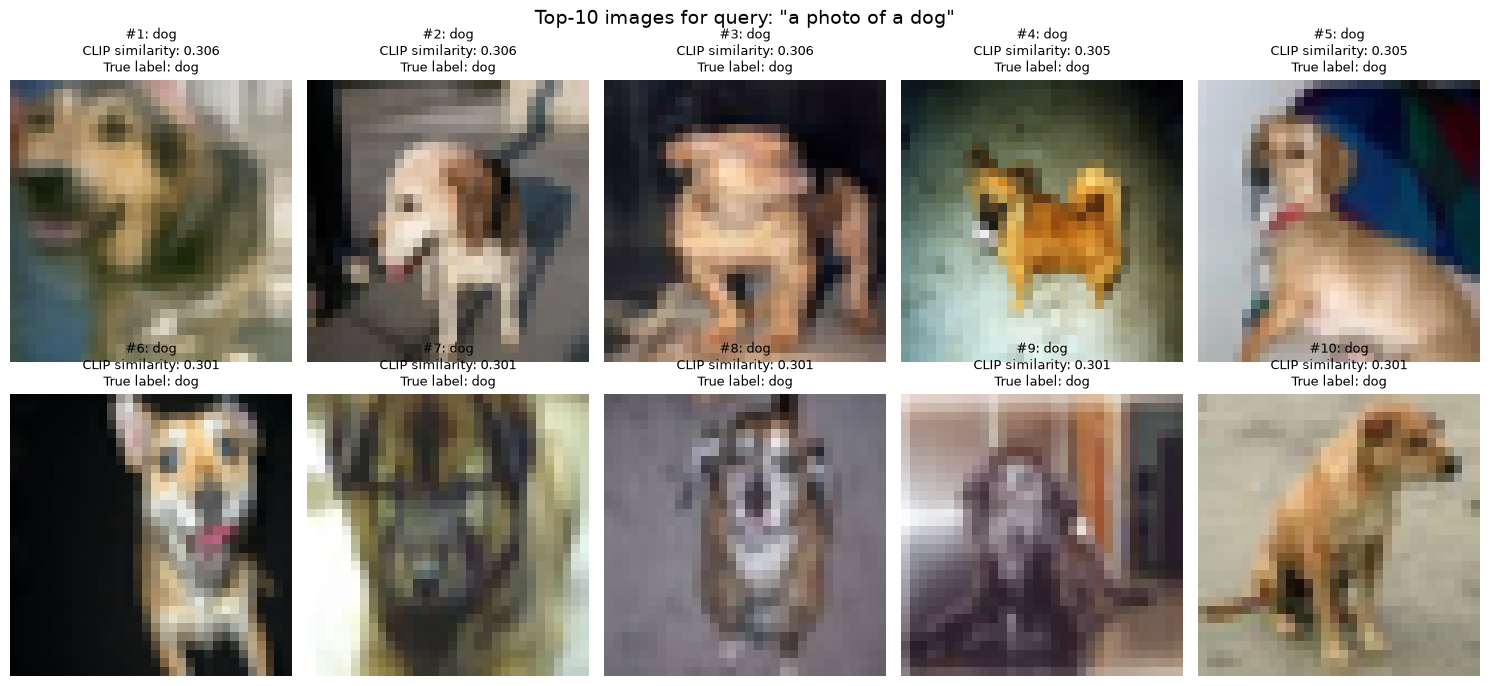

In [8]:
# Используем результаты поиска из предыдущей ячейки
query = retrieval_report["query"]
results = retrieval_report["results"]

n_images = len(results)
n_cols = 5
n_rows = math.ceil(n_images / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.5 * n_rows))
axes = axes.flatten()

for ax, result in zip(axes, results):
    # test_index — индекс изображения в исходном тестовом наборе CIFAR-10
    image_index = result["test_index"]
    image, true_label = cifar_test[image_index]

    ax.imshow(image)
    ax.set_title(
        f'#{result["rank"]}: {result["class_name"]}\n'
        f'CLIP similarity: {result["similarity"]:.3f}\n'
        f'True label: {classes[true_label]}',
        fontsize=9
    )
    ax.axis("off")

# Скрываем неиспользуемые ячейки
for ax in axes[n_images:]:
    ax.axis("off")

fig.suptitle(f'Top-{n_images} images for query: "{query}"', fontsize=14)
plt.tight_layout()
plt.show()

### Релевантность поиска по классам

*Вес: 1 балл.*

**Постановка.** Precision@10 и recall@10 требуют фиксированного определения релевантности.

Выполните следующие действия:
1. Задайте релевантность как совпадение с классом запроса.
2. Вычислите метрики поиска для каждого класса.

**Результат.** retrieval_report.json с фактическими значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
model.eval()

# Загружаем данные индекса, созданного в предыдущей ячейке
index_path = ARTIFACTS / "clip_index.pt"
index_data = torch.load(index_path, map_location="cpu", weights_only=False)

image_embeddings = index_data["embeddings"].float()
image_labels = index_data["labels"].long()
index_classes = index_data["classes"]

# На всякий случай нормализуем признаки изображений
image_embeddings = F.normalize(image_embeddings, p=2, dim=-1)

k = min(10, len(image_labels))
class_results = []

with torch.inference_mode():
    for class_id, class_name in enumerate(index_classes):
        query = f"a photo of a {class_name}"

        # Получаем текстовый эмбеддинг запроса
        tokens = tokenizer([query]).to(DEVICE)
        text_embedding = model.encode_text(tokens).float()
        text_embedding = F.normalize(text_embedding, p=2, dim=-1).cpu().squeeze(0)

        # Ранжируем все изображения по сходству с запросом
        similarities = image_embeddings @ text_embedding
        top_positions = torch.topk(similarities, k=k).indices
        retrieved_labels = image_labels[top_positions]

        # Релевантность определяется совпадением класса
        relevant_total = int((image_labels == class_id).sum().item())
        relevant_retrieved = int((retrieved_labels == class_id).sum().item())

        precision_at_k = relevant_retrieved / k if k > 0 else 0.0
        recall_at_k = (
            relevant_retrieved / relevant_total
            if relevant_total > 0
            else 0.0
        )

        class_results.append({
            "class_id": class_id,
            "class_name": class_name,
            "query": query,
            "k": k,
            "relevant_in_index": relevant_total,
            "relevant_in_top_k": relevant_retrieved,
            "precision_at_10": precision_at_k,
            "recall_at_10": recall_at_k,
        })

        print(
            f"{class_name:12s} | "
            f"Precision@{k}={precision_at_k:.4f} | "
            f"Recall@{k}={recall_at_k:.4f} | "
            f"релевантных в топ-{k}: {relevant_retrieved}/{k}"
        )

# Усреднение метрик по классам
macro_precision = sum(r["precision_at_10"] for r in class_results) / len(class_results)
macro_recall = sum(r["recall_at_10"] for r in class_results) / len(class_results)

retrieval_metrics_report = {
    "dataset": "CIFAR-10",
    "model_name": index_data["model_name"],
    "pretrained": index_data["pretrained"],
    "fast_dev_run": index_data["fast_dev_run"],
    "index_size": len(image_labels),
    "relevance_definition": "An image is relevant if its true label matches the query class.",
    "k": k,
    "macro_precision_at_10": macro_precision,
    "macro_recall_at_10": macro_recall,
    "per_class": class_results,
}

report_path = ARTIFACTS / "retrieval_report.json"
with report_path.open("w", encoding="utf-8") as f:
    json.dump(retrieval_metrics_report, f, ensure_ascii=False, indent=2)

print(f"\nMacro Precision@{k}: {macro_precision:.4f}")
print(f"Macro Recall@{k}:    {macro_recall:.4f}")
print(f"Отчёт сохранён: {report_path.resolve()}")

airplane     | Precision@10=1.0000 | Recall@10=0.0100 | релевантных в топ-10: 10/10
automobile   | Precision@10=1.0000 | Recall@10=0.0100 | релевантных в топ-10: 10/10
bird         | Precision@10=1.0000 | Recall@10=0.0100 | релевантных в топ-10: 10/10
cat          | Precision@10=1.0000 | Recall@10=0.0100 | релевантных в топ-10: 10/10
deer         | Precision@10=1.0000 | Recall@10=0.0100 | релевантных в топ-10: 10/10
dog          | Precision@10=1.0000 | Recall@10=0.0100 | релевантных в топ-10: 10/10
frog         | Precision@10=1.0000 | Recall@10=0.0100 | релевантных в топ-10: 10/10
horse        | Precision@10=1.0000 | Recall@10=0.0100 | релевантных в топ-10: 10/10
ship         | Precision@10=1.0000 | Recall@10=0.0100 | релевантных в топ-10: 10/10
truck        | Precision@10=1.0000 | Recall@10=0.0100 | релевантных в топ-10: 10/10

Macro Precision@10: 1.0000
Macro Recall@10:    0.0100
Отчёт сохранён: C:\Anton\16 триместр\SOTA\lab5\artifacts\retrieval_report.json


### Данные для обучаемой проекции

*Вес: 1 балл.*

**Постановка.** Одинаковые подписи в мини-партии не являются отрицательными парами. Проекция обучается по классовым прототипам.

Выполните следующие действия:
1. Создайте две линейные проекции и инициализируйте тождественно.
2. Подготовьте независимые train-пары и optimizer.

**Результат.** image_head, text_head и train_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
# Размерность исходных эмбеддингов CLIP
with torch.inference_mode():
    sample_tokens = tokenizer(["a photo of a dog"]).to(DEVICE)
    text_dim = model.encode_text(sample_tokens).shape[-1]

    sample_images, _ = next(iter(loader))
    image_dim = model.encode_image(sample_images[:1].to(DEVICE)).shape[-1]

# Для контрастивного обучения обе проекции должны иметь общую выходную размерность
PROJECTION_DIM = min(image_dim, text_dim)

class ProjectionHead(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, output_dim)

        # Инициализация тождественным отображением, если размеры совпадают.
        # Иначе сохраняем максимально близкую к тождественной инициализацию.
        with torch.no_grad():
            self.linear.weight.zero_()
            self.linear.bias.zero_()
            n = min(input_dim, output_dim)
            self.linear.weight[:n, :n].copy_(torch.eye(n))

    def forward(self, x):
        return F.normalize(self.linear(x), p=2, dim=-1)

image_head = ProjectionHead(image_dim, PROJECTION_DIM).to(DEVICE)
text_head = ProjectionHead(text_dim, PROJECTION_DIM).to(DEVICE)

# Базовый CLIP заморожен: обучаются только две проекции
model.eval()
for parameter in model.parameters():
    parameter.requires_grad = False

# Отдельный набор обучающих пар, независимый от тестового индекса
train_loader = DataLoader(
    train_pairs,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE == "cuda"),
    generator=torch.Generator().manual_seed(SEED),
)

# Оптимизатор обновляет параметры обеих проекций
LEARNING_RATE = 1e-3
optimizer = torch.optim.AdamW(
    list(image_head.parameters()) + list(text_head.parameters()),
    lr=LEARNING_RATE,
    weight_decay=1e-4,
)

print({
    "image_dim": image_dim,
    "text_dim": text_dim,
    "projection_dim": PROJECTION_DIM,
    "train_pairs": len(train_pairs),
    "batches": len(train_loader),
    "batch_size": BATCH_SIZE,
    "optimizer": type(optimizer).__name__,
    "trainable_parameters": sum(
        p.numel() for p in image_head.parameters() if p.requires_grad
    ) + sum(
        p.numel() for p in text_head.parameters() if p.requires_grad
    ),
})

{'image_dim': 512, 'text_dim': 512, 'projection_dim': 512, 'train_pairs': 20000, 'batches': 625, 'batch_size': 32, 'optimizer': 'AdamW', 'trainable_parameters': 525312}


### Обучение проекций по меткам

*Вес: 1 балл.*

**Постановка.** Классовая cross-entropy не объявляет одинаковые captions взаимными негативами.

Выполните следующие действия:
1. Обучите проекции по logits изображения против всех десяти текстовых прототипов.
2. Сохраните обученные веса.

**Результат.** clip_projection.pt после оптимизации на train.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
# Параметры обучения
NUM_EPOCHS = 2 if FAST_DEV_RUN else 5
PROJECTION_DIM = image_head.linear.out_features
PROJECTION_PATH = ARTIFACTS / "clip_projection.pt"
LOGIT_SCALE = 10.0

# Текстовые прототипы всех классов.
# Используем одинаковый шаблон, чтобы каждому классу соответствовал один прототип.
class_prompts = [f"a photo of a {name}" for name in classes]

model.eval()
for parameter in model.parameters():
    parameter.requires_grad = False

with torch.inference_mode():
    tokens = tokenizer(class_prompts).to(DEVICE)
    class_text_features = model.encode_text(tokens).float()
    class_text_features = F.normalize(class_text_features, p=2, dim=-1)

# Преобразуем inference-тензор в обычный тензор,
# который можно использовать при вычислении градиентов
class_text_features = class_text_features.clone()

# Кэшируем признаки обучающих изображений:
# замороженный CLIP не нужно повторно запускать на каждой эпохе.
cached_image_features = []
cached_labels = []

with torch.inference_mode():
    for images, captions, labels in train_loader:
        images = images.to(DEVICE)
        features = model.encode_image(images).float()
        features = F.normalize(features, p=2, dim=-1)

        cached_image_features.append(features.cpu())
        cached_labels.append(labels.cpu())

cached_image_features = torch.cat(cached_image_features, dim=0)
cached_labels = torch.cat(cached_labels, dim=0).long()

feature_dataset = TensorDataset(cached_image_features, cached_labels)
feature_loader = DataLoader(
    feature_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)

# Проверяем, что обе проекции имеют совместимую размерность
if image_head.linear.in_features != cached_image_features.shape[1]:
    raise ValueError("Размерность image_head не совпадает с размерностью признаков изображений.")
if text_head.linear.in_features != class_text_features.shape[1]:
    raise ValueError("Размерность text_head не совпадает с размерностью текстовых признаков.")
if image_head.linear.out_features != text_head.linear.out_features:
    raise ValueError("У image_head и text_head должны совпадать выходные размерности.")

# Оптимизатор обновляет параметры обеих проекций
optimizer = torch.optim.AdamW(
    list(image_head.parameters()) + list(text_head.parameters()),
    lr=1e-3,
    weight_decay=1e-4,
)

start_epoch = 0
history = []

# Возобновляем обучение, если есть совместимый чекпойнт
if PROJECTION_PATH.exists():
    checkpoint = torch.load(PROJECTION_PATH, map_location=DEVICE, weights_only=False)
    same_config = (
        checkpoint.get("classes") == classes
        and checkpoint.get("fast_dev_run") == FAST_DEV_RUN
        and checkpoint.get("projection_dim") == PROJECTION_DIM
        and checkpoint.get("model_name") == MODEL_NAME
        and checkpoint.get("pretrained") == PRETRAINED
    )
    if same_config:
        image_head.load_state_dict(checkpoint["image_head"])
        text_head.load_state_dict(checkpoint["text_head"])
        if "optimizer" in checkpoint:
            optimizer.load_state_dict(checkpoint["optimizer"])
        start_epoch = int(checkpoint.get("epoch", 0))
        history = checkpoint.get("history", [])
        print(f"Возобновляем обучение с эпохи {start_epoch + 1}.")
    else:
        print("Найден чекпойнт с другой конфигурацией; начинаем обучение заново.")

image_head.train()
text_head.train()

for epoch in range(start_epoch, NUM_EPOCHS):
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    # Проецируем прототипы классов; градиенты обновляют text_head
    projected_text = text_head(class_text_features.to(DEVICE))

    for image_features, labels in feature_loader:
        image_features = image_features.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        projected_images = image_head(image_features)

        # Логиты каждого изображения относительно всех десяти классов
        logits = LOGIT_SCALE * projected_images @ projected_text.T

        # Правильный класс задаётся меткой CIFAR-10
        loss = F.cross_entropy(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size

        # После обновления параметров обновляем текстовые прототипы
        projected_text = text_head(class_text_features.to(DEVICE))

    epoch_loss = total_loss / max(total_samples, 1)
    epoch_accuracy = total_correct / max(total_samples, 1)

    history.append({
        "epoch": epoch + 1,
        "train_loss": epoch_loss,
        "train_accuracy": epoch_accuracy,
    })

    print(
        f"Эпоха {epoch + 1}/{NUM_EPOCHS} | "
        f"loss={epoch_loss:.4f} | accuracy={epoch_accuracy:.4f}"
    )

    # Сохраняем после каждой эпохи, чтобы можно было продолжить обучение
    torch.save({
        "epoch": epoch + 1,
        "image_head": image_head.state_dict(),
        "text_head": text_head.state_dict(),
        "optimizer": optimizer.state_dict(),
        "history": history,
        "classes": classes,
        "model_name": MODEL_NAME,
        "pretrained": PRETRAINED,
        "projection_dim": PROJECTION_DIM,
        "fast_dev_run": FAST_DEV_RUN,
        "logit_scale": LOGIT_SCALE,
    }, PROJECTION_PATH)

# Готовим проекции к последующему использованию
image_head.eval()
text_head.eval()

training_report = {
    "checkpoint": str(PROJECTION_PATH),
    "epochs_completed": history[-1]["epoch"] if history else start_epoch,
    "num_train_samples": len(cached_labels),
    "fast_dev_run": FAST_DEV_RUN,
    "history": history,
}
print(json.dumps(training_report, ensure_ascii=False, indent=2))
print(f"Веса сохранены: {PROJECTION_PATH.resolve()}")

Эпоха 1/5 | loss=0.1479 | accuracy=0.9556
Эпоха 2/5 | loss=0.1022 | accuracy=0.9647
Эпоха 3/5 | loss=0.0899 | accuracy=0.9699
Эпоха 4/5 | loss=0.0808 | accuracy=0.9730
Эпоха 5/5 | loss=0.0754 | accuracy=0.9741
{
  "checkpoint": "artifacts\\clip_projection.pt",
  "epochs_completed": 5,
  "num_train_samples": 20000,
  "fast_dev_run": false,
  "history": [
    {
      "epoch": 1,
      "train_loss": 0.14786557524502278,
      "train_accuracy": 0.95555
    },
    {
      "epoch": 2,
      "train_loss": 0.10216073900610209,
      "train_accuracy": 0.96475
    },
    {
      "epoch": 3,
      "train_loss": 0.08989155101403594,
      "train_accuracy": 0.96995
    },
    {
      "epoch": 4,
      "train_loss": 0.08083076652660966,
      "train_accuracy": 0.973
    },
    {
      "epoch": 5,
      "train_loss": 0.0753707444820553,
      "train_accuracy": 0.97415
    }
  ]
}
Веса сохранены: C:\Anton\16 триместр\SOTA\lab5\artifacts\clip_projection.pt


### Оценка адаптированного поиска

*Вес: 1 балл.*

**Постановка.** После обучения все варианты сравниваются на одинаковых test-изображениях.

Выполните следующие действия:
1. Обновите test-эмбеддинги двумя проекциями.
2. Сравните accuracy и среднюю precision@10 до и после обучения.

**Результат.** adaptation.json с измеренными baseline и adapted значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [12]:
# --------------------------------------------------
# 1. Настройки и проверка обученных проекций
# --------------------------------------------------

ADAPTATION_PATH = ARTIFACTS / "adaptation.json"
PROJECTION_PATH = ARTIFACTS / "clip_projection.pt"
TOP_K = 10

if not PROJECTION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл обученных проекций: {PROJECTION_PATH}. "
        "Сначала выполните задание по обучению projection heads."
    )

checkpoint = torch.load(
    PROJECTION_PATH,
    map_location=DEVICE,
    weights_only=False,
)

if checkpoint.get("classes") != classes:
    raise ValueError("Классы в checkpoint не совпадают с текущим набором данных.")

if checkpoint.get("fast_dev_run") != FAST_DEV_RUN:
    raise ValueError(
        "Checkpoint создан в другом режиме FAST_DEV_RUN. "
        "Обучите проекции в текущем режиме, прежде чем проводить сравнение."
    )

image_head.load_state_dict(checkpoint["image_head"])
text_head.load_state_dict(checkpoint["text_head"])

model.eval()
image_head.eval()
text_head.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

# --------------------------------------------------
# 2. Текстовые эмбеддинги для всех классов
# --------------------------------------------------

class_prompts = [f"a photo of a {name}" for name in classes]
tokens = tokenizer(class_prompts).to(DEVICE)

with torch.no_grad():
    # Исходные CLIP-текстовые эмбеддинги
    baseline_text_features = model.encode_text(tokens).float()
    baseline_text_features = F.normalize(
        baseline_text_features, p=2, dim=-1
    )

    # Текстовые эмбеддинги после адаптации
    adapted_text_features = text_head(baseline_text_features)
    adapted_text_features = F.normalize(
        adapted_text_features, p=2, dim=-1
    )

# --------------------------------------------------
# 3. Извлечение test-эмбеддингов
#    Используем один и тот же набор изображений
# --------------------------------------------------

test_eval_loader = DataLoader(
    ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE == "cuda"),
)

image_feature_batches = []
label_batches = []

with torch.no_grad():
    for images, labels in test_eval_loader:
        images = images.to(DEVICE)

        features = model.encode_image(images).float()
        features = F.normalize(features, p=2, dim=-1)

        image_feature_batches.append(features.cpu())
        label_batches.append(labels.cpu())

baseline_image_features = torch.cat(image_feature_batches, dim=0).to(DEVICE)
test_labels = torch.cat(label_batches, dim=0).long().to(DEVICE)

# Применяем обученную проекцию к тем же изображениям
with torch.no_grad():
    adapted_image_features = image_head(baseline_image_features)
    adapted_image_features = F.normalize(
        adapted_image_features, p=2, dim=-1
    )

num_images = len(test_labels)
num_classes = len(classes)
k = min(TOP_K, num_images)

# --------------------------------------------------
# 4. Accuracy: классификация по текстовым прототипам
# --------------------------------------------------

with torch.no_grad():
    # Baseline: исходные CLIP-эмбеддинги
    baseline_logits = baseline_image_features @ baseline_text_features.T
    baseline_predictions = baseline_logits.argmax(dim=1)
    baseline_accuracy = (
        baseline_predictions == test_labels
    ).float().mean().item()

    # Adapted: проекции изображений и текстов
    adapted_logits = adapted_image_features @ adapted_text_features.T
    adapted_predictions = adapted_logits.argmax(dim=1)
    adapted_accuracy = (
        adapted_predictions == test_labels
    ).float().mean().item()

# --------------------------------------------------
# 5. Mean Precision@10 для текстового поиска
# --------------------------------------------------

def calculate_precision_at_k(image_features, text_features, labels, class_names, k):
    """
    Для каждого класса выполняет текстовый поиск по всем test-изображениям.
    Precision@k = число релевантных результатов в top-k / k.
    Итоговая метрика — среднее Precision@k по классам.
    """
    per_class_precision = {}

    with torch.no_grad():
        similarities = text_features @ image_features.T

        for class_id, class_name in enumerate(class_names):
            top_indices = similarities[class_id].topk(k=k).indices
            retrieved_labels = labels[top_indices]
            relevant = (retrieved_labels == class_id).float()

            precision = relevant.sum().item() / k
            per_class_precision[class_name] = precision

    mean_precision = sum(per_class_precision.values()) / len(per_class_precision)

    return mean_precision, per_class_precision


baseline_precision_at_10, baseline_per_class_precision = (
    calculate_precision_at_k(
        baseline_image_features,
        baseline_text_features,
        test_labels,
        classes,
        k,
    )
)

adapted_precision_at_10, adapted_per_class_precision = (
    calculate_precision_at_k(
        adapted_image_features,
        adapted_text_features,
        test_labels,
        classes,
        k,
    )
)

# --------------------------------------------------
# 6. Сохранение результатов
# --------------------------------------------------

results = {
    "model_name": MODEL_NAME,
    "pretrained": PRETRAINED,
    "fast_dev_run": FAST_DEV_RUN,
    "num_test_images": num_images,
    "num_classes": num_classes,
    "retrieval_k": k,
    "metrics": {
        "baseline": {
            "accuracy": baseline_accuracy,
            "mean_precision_at_10": baseline_precision_at_10,
            "precision_at_10_per_class": baseline_per_class_precision,
        },
        "adapted": {
            "accuracy": adapted_accuracy,
            "mean_precision_at_10": adapted_precision_at_10,
            "precision_at_10_per_class": adapted_per_class_precision,
        },
        "delta_adapted_minus_baseline": {
            "accuracy": adapted_accuracy - baseline_accuracy,
            "mean_precision_at_10": (
                adapted_precision_at_10 - baseline_precision_at_10
            ),
        },
    },
}

with open(ADAPTATION_PATH, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print(f"Число тестовых изображений: {num_images}")
print(f"Режим FAST_DEV_RUN: {FAST_DEV_RUN}")
print()
print("Метрика                 Baseline     Adapted      Изменение")
print(
    f"Accuracy                {baseline_accuracy:>8.4f}     "
    f"{adapted_accuracy:>8.4f}     "
    f"{adapted_accuracy - baseline_accuracy:+.4f}"
)
print(
    f"Mean Precision@{k:<2}       {baseline_precision_at_10:>8.4f}     "
    f"{adapted_precision_at_10:>8.4f}     "
    f"{adapted_precision_at_10 - baseline_precision_at_10:+.4f}"
)
print()
print(f"Результаты сохранены в: {ADAPTATION_PATH}")

Число тестовых изображений: 10000
Режим FAST_DEV_RUN: False

Метрика                 Baseline     Adapted      Изменение
Accuracy                  0.9366       0.9637     +0.0271
Mean Precision@10         1.0000       1.0000     +0.0000

Результаты сохранены в: artifacts\adaptation.json


### Лучшие и худшие результаты поиска

*Вес: 1 балл.*

**Постановка.** Конкретные ошибки поиска дополняют усреднённую precision@10.

Выполните следующие действия:
1. Выберите лучший и худший класс по precision@10.
2. Сохраните индексы и истинные классы найденных объектов.

**Результат.** search_examples.json с примерами реальных изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [13]:
# --------------------------------------------------
# 1. Проверяем, что необходимые результаты существуют
# --------------------------------------------------

ADAPTATION_PATH = ARTIFACTS / "adaptation.json"
PROJECTION_PATH = ARTIFACTS / "clip_projection.pt"
SEARCH_EXAMPLES_PATH = ARTIFACTS / "search_examples.json"

if not ADAPTATION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл {ADAPTATION_PATH}. "
        "Сначала выполните задание «Оценка адаптированного поиска»."
    )

if not PROJECTION_PATH.exists():
    raise FileNotFoundError(
        f"Не найден файл {PROJECTION_PATH}. "
        "Сначала обучите проекционные головы."
    )

with open(ADAPTATION_PATH, "r", encoding="utf-8") as f:
    adaptation_results = json.load(f)

checkpoint = torch.load(
    PROJECTION_PATH,
    map_location=DEVICE,
    weights_only=False,
)

if checkpoint.get("classes") != classes:
    raise ValueError("Классы checkpoint не совпадают с текущим набором данных.")

if checkpoint.get("fast_dev_run") != FAST_DEV_RUN:
    raise ValueError(
        "Режим FAST_DEV_RUN не совпадает с режимом обученных проекций."
    )

if adaptation_results.get("fast_dev_run") != FAST_DEV_RUN:
    raise ValueError(
        "Режим FAST_DEV_RUN не совпадает с результатами оценки адаптации."
    )

image_head.load_state_dict(checkpoint["image_head"])
text_head.load_state_dict(checkpoint["text_head"])

model.eval()
image_head.eval()
text_head.eval()

# --------------------------------------------------
# 2. Определяем лучший и худший классы по Precision@10
# --------------------------------------------------

per_class_precision = adaptation_results["metrics"]["adapted"][
    "precision_at_10_per_class"
]

if not per_class_precision:
    raise ValueError("В adaptation.json нет значений Precision@10 по классам.")

best_class = max(per_class_precision, key=per_class_precision.get)
worst_class = min(per_class_precision, key=per_class_precision.get)

# --------------------------------------------------
# 3. Получаем тестовые эмбеддинги и истинные метки
# --------------------------------------------------

# ds — тестовый набор, созданный в предыдущих заданиях.
# ds.indices содержит исходные индексы изображений в CIFAR-10.
test_indices = list(ds.indices)

if len(test_indices) != len(ds):
    raise ValueError("Количество исходных индексов не совпадает с размером ds.")

image_batches = []
label_batches = []

with torch.no_grad():
    for images, labels in loader:
        images = images.to(DEVICE)

        image_features = model.encode_image(images).float()
        image_features = F.normalize(image_features, p=2, dim=-1)

        image_features = image_head(image_features)
        image_features = F.normalize(image_features, p=2, dim=-1)

        image_batches.append(image_features.cpu())
        label_batches.append(labels.cpu())

test_image_features = torch.cat(image_batches, dim=0).to(DEVICE)
test_labels = torch.cat(label_batches, dim=0).long()

if len(test_labels) != len(test_indices):
    raise ValueError(
        "Количество тестовых меток не совпадает с количеством исходных индексов."
    )

# --------------------------------------------------
# 4. Создаём текстовые запросы и ранжируем изображения
# --------------------------------------------------

prompts = [f"a photo of a {name}" for name in classes]
tokens = tokenizer(prompts).to(DEVICE)

with torch.no_grad():
    text_features = model.encode_text(tokens).float()
    text_features = F.normalize(text_features, p=2, dim=-1)

    text_features = text_head(text_features)
    text_features = F.normalize(text_features, p=2, dim=-1)

    # Матрица: число классов x число тестовых изображений
    similarities = text_features @ test_image_features.T

# --------------------------------------------------
# 5. Сохраняем top-10 для лучшего и худшего классов
# --------------------------------------------------

K = min(10, len(test_indices))


def build_search_example(class_name):
    """Формирует сведения о top-k результатах поиска для одного класса."""
    class_id = classes.index(class_name)

    scores, positions = similarities[class_id].topk(k=K)

    retrieved = []
    for rank, (position, score) in enumerate(
        zip(positions.cpu().tolist(), scores.cpu().tolist()),
        start=1,
    ):
        true_label = int(test_labels[position].item())
        original_index = int(test_indices[position])

        retrieved.append({
            "rank": rank,
            "dataset_index": original_index,
            "true_label_id": true_label,
            "true_class": classes[true_label],
            "similarity": float(score),
            "relevant": true_label == class_id,
        })

    precision_at_k = sum(item["relevant"] for item in retrieved) / K

    return {
        "query_class": class_name,
        "query_class_id": class_id,
        "query": f"a photo of a {class_name}",
        "precision_at_10": precision_at_k,
        "retrieved_images": retrieved,
    }


best_example = build_search_example(best_class)
worst_example = build_search_example(worst_class)

search_examples = {
    "model_name": MODEL_NAME,
    "pretrained": PRETRAINED,
    "fast_dev_run": FAST_DEV_RUN,
    "num_test_images": len(test_indices),
    "top_k": K,
    "selection_metric": "adapted precision_at_10",
    "best": best_example,
    "worst": worst_example,
}

with open(SEARCH_EXAMPLES_PATH, "w", encoding="utf-8") as f:
    json.dump(search_examples, f, ensure_ascii=False, indent=2)

# --------------------------------------------------
# 6. Выводим краткую сводку
# --------------------------------------------------

print(f"Лучший класс: {best_class}")
print(f"Precision@{K}: {best_example['precision_at_10']:.3f}")
for item in best_example["retrieved_images"]:
    print(
        f"  rank={item['rank']:2d}, "
        f"index={item['dataset_index']:5d}, "
        f"true_class={item['true_class']:<12}, "
        f"similarity={item['similarity']:.4f}, "
        f"relevant={item['relevant']}"
    )

print(f"\nХудший класс: {worst_class}")
print(f"Precision@{K}: {worst_example['precision_at_10']:.3f}")
for item in worst_example["retrieved_images"]:
    print(
        f"  rank={item['rank']:2d}, "
        f"index={item['dataset_index']:5d}, "
        f"true_class={item['true_class']:<12}, "
        f"similarity={item['similarity']:.4f}, "
        f"relevant={item['relevant']}"
    )

print(f"\nРезультаты сохранены в: {SEARCH_EXAMPLES_PATH}")

Лучший класс: airplane
Precision@10: 1.000
  rank= 1, index=  192, true_class=airplane    , similarity=0.9486, relevant=True
  rank= 2, index= 9980, true_class=airplane    , similarity=0.9435, relevant=True
  rank= 3, index= 4901, true_class=airplane    , similarity=0.9434, relevant=True
  rank= 4, index= 5516, true_class=airplane    , similarity=0.9381, relevant=True
  rank= 5, index= 6284, true_class=airplane    , similarity=0.9375, relevant=True
  rank= 6, index= 9512, true_class=airplane    , similarity=0.9368, relevant=True
  rank= 7, index= 8812, true_class=airplane    , similarity=0.9359, relevant=True
  rank= 8, index=  526, true_class=airplane    , similarity=0.9340, relevant=True
  rank= 9, index= 6334, true_class=airplane    , similarity=0.9304, relevant=True
  rank=10, index= 1719, true_class=airplane    , similarity=0.9301, relevant=True

Худший класс: airplane
Precision@10: 1.000
  rank= 1, index=  192, true_class=airplane    , similarity=0.9486, relevant=True
  rank= 2, 

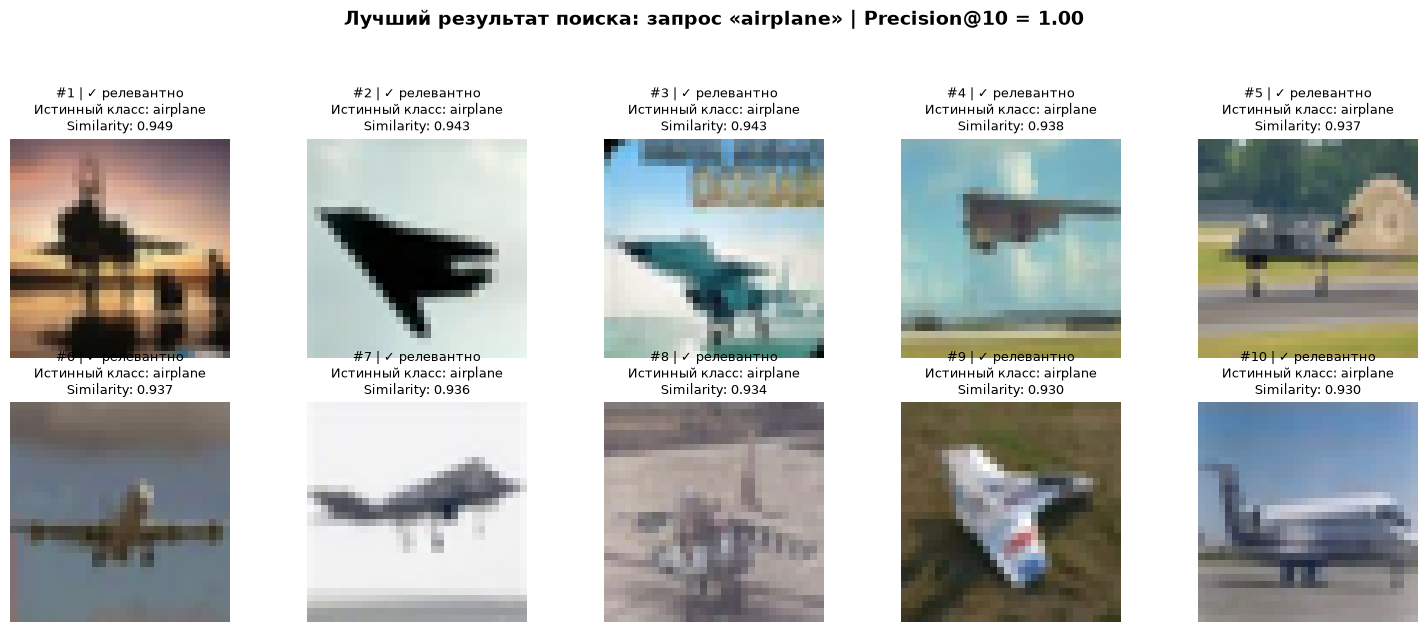

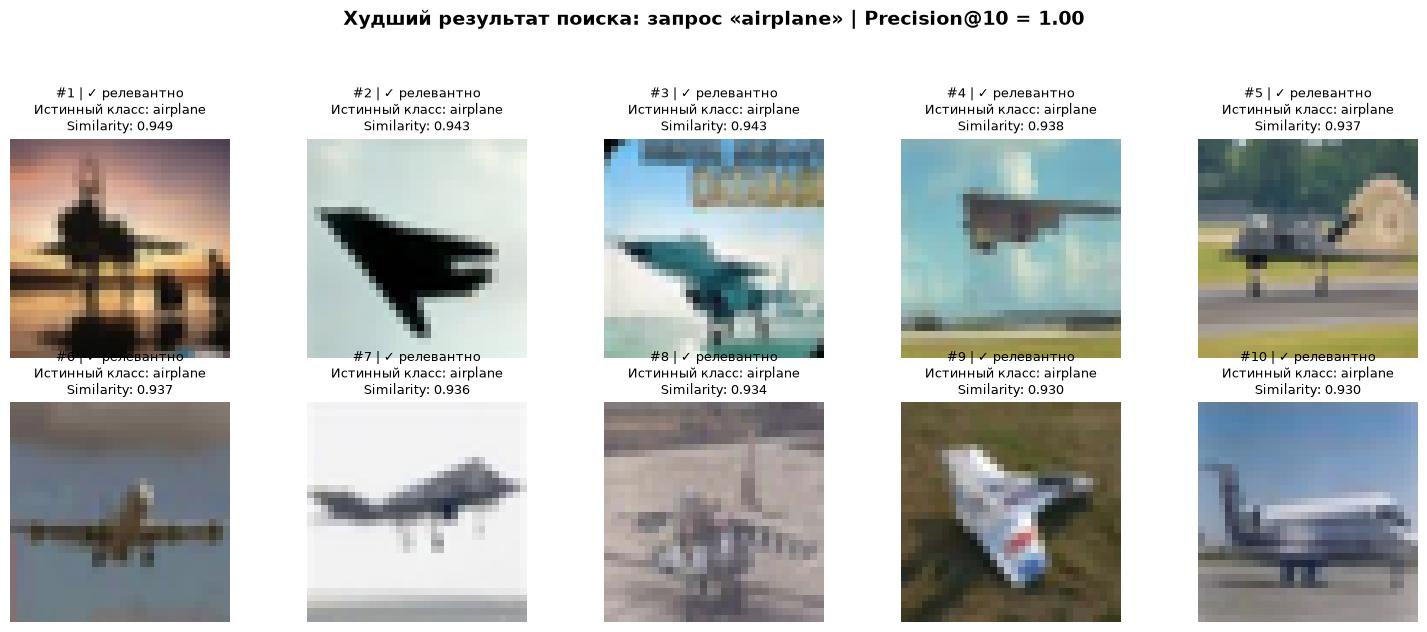

In [14]:
from PIL import Image

SEARCH_EXAMPLES_PATH = ARTIFACTS / "search_examples.json"

with open(SEARCH_EXAMPLES_PATH, "r", encoding="utf-8") as f:
    search_examples = json.load(f)


def show_search_results(example, dataset, title, columns=5):
    results = example["retrieved_images"]
    count = len(results)
    rows = (count + columns - 1) // columns

    fig, axes = plt.subplots(
        rows, columns,
        figsize=(columns * 3, rows * 3.2),
        squeeze=False
    )
    fig.suptitle(
        f"{title}: запрос «{example['query_class']}» | "
        f"Precision@{len(results)} = {example['precision_at_10']:.2f}",
        fontsize=14,
        fontweight="bold"
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, item in zip(axes.flat, results):
        # dataset_index — индекс в исходном CIFAR-10 test dataset
        image, _ = dataset[item["dataset_index"]]

        # Поддерживаем PIL-изображения и тензоры
        if isinstance(image, Image.Image):
            ax.imshow(image)
        else:
            image = image.detach().cpu()
            if image.ndim == 3 and image.shape[0] in (1, 3, 4):
                image = image.permute(1, 2, 0)
            ax.imshow(image.squeeze(), cmap="gray" if image.shape[-1:] == (1,) else None)

        correct = item["relevant"]
        status = "✓ релевантно" if correct else "✗ ошибка"

        ax.set_title(
            f"#{item['rank']} | {status}\n"
            f"Истинный класс: {item['true_class']}\n"
            f"Similarity: {item['similarity']:.3f}",
            fontsize=9
        )
        ax.axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()


# Исходный тестовый набор CIFAR-10
show_search_results(
    search_examples["best"],
    cifar_test,
    title="Лучший результат поиска"
)

show_search_results(
    search_examples["worst"],
    cifar_test,
    title="Худший результат поиска"
)

### Поклассовая динамика поиска

*Вес: 1 балл.*

**Постановка.** Средний показатель может скрывать ухудшение поиска для отдельных категорий.

Выполните следующие действия:
1. Повторно вычислите адаптированную precision@10 по каждому классу.
2. Сопоставьте её с исходной precision@10.

**Результат.** retrieval_deltas.json с наблюдаемыми поклассовыми изменениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [15]:
# --------------------------------------------------
# 1. Пути к артефактам и проверка входных данных
# --------------------------------------------------

INDEX_PATH = ARTIFACTS / "clip_index.pt"
PROJECTION_PATH = ARTIFACTS / "clip_projection.pt"
DELTA_PATH = ARTIFACTS / "retrieval_deltas.json"

if not INDEX_PATH.exists():
    raise FileNotFoundError(
        f"Не найден индекс изображений: {INDEX_PATH}. "
        "Сначала выполните задание по созданию CLIP-индекса."
    )

if not PROJECTION_PATH.exists():
    raise FileNotFoundError(
        f"Не найдены обученные проекции: {PROJECTION_PATH}. "
        "Сначала выполните обучение projection heads."
    )

index_data = torch.load(
    INDEX_PATH, map_location="cpu", weights_only=False
)
checkpoint = torch.load(
    PROJECTION_PATH, map_location=DEVICE, weights_only=False
)

if index_data["classes"] != classes:
    raise ValueError("Классы в индексе не совпадают с текущими классами.")

if checkpoint.get("classes") != classes:
    raise ValueError("Классы checkpoint не совпадают с текущими классами.")

if index_data.get("fast_dev_run") != FAST_DEV_RUN:
    raise ValueError(
        "Индекс создан в другом режиме FAST_DEV_RUN. "
        "Создайте индекс заново в текущем режиме."
    )

if checkpoint.get("fast_dev_run") != FAST_DEV_RUN:
    raise ValueError(
        "Проекции обучены в другом режиме FAST_DEV_RUN. "
        "Обучите проекции заново в текущем режиме."
    )

image_head.load_state_dict(checkpoint["image_head"])
text_head.load_state_dict(checkpoint["text_head"])

model.eval()
image_head.eval()
text_head.eval()

# --------------------------------------------------
# 2. Вычисляем текстовые эмбеддинги классов
# --------------------------------------------------

prompts = [f"a photo of a {class_name}" for class_name in classes]
tokens = tokenizer(prompts).to(DEVICE)

with torch.no_grad():
    baseline_text_features = model.encode_text(tokens).float()
    baseline_text_features = F.normalize(
        baseline_text_features, p=2, dim=-1
    )

    adapted_text_features = text_head(baseline_text_features)
    adapted_text_features = F.normalize(
        adapted_text_features, p=2, dim=-1
    )

# --------------------------------------------------
# 3. Получаем эмбеддинги одного и того же test-набора
# --------------------------------------------------

test_eval_loader = DataLoader(
    ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE == "cuda"),
)

image_batches = []
label_batches = []

with torch.no_grad():
    for images, labels in test_eval_loader:
        images = images.to(DEVICE)

        features = model.encode_image(images).float()
        features = F.normalize(features, p=2, dim=-1)

        image_batches.append(features.cpu())
        label_batches.append(labels.cpu())

baseline_image_features = torch.cat(image_batches, dim=0).to(DEVICE)
test_labels = torch.cat(label_batches, dim=0).long().to(DEVICE)

with torch.no_grad():
    adapted_image_features = image_head(baseline_image_features)
    adapted_image_features = F.normalize(
        adapted_image_features, p=2, dim=-1
    )

# --------------------------------------------------
# 4. Функция поклассовой Precision@10
# --------------------------------------------------

K = min(10, len(test_labels))


def precision_at_k_per_class(
    image_features, text_features, labels, class_names, k
):
    """
    Для каждого класса ранжирует все тестовые изображения
    по сходству с текстовым запросом и считает Precision@k.
    """
    per_class = {}

    with torch.no_grad():
        similarities = text_features @ image_features.T

        for class_id, class_name in enumerate(class_names):
            top_indices = similarities[class_id].topk(k=k).indices
            retrieved_labels = labels[top_indices]

            relevant_count = (retrieved_labels == class_id).sum().item()
            per_class[class_name] = relevant_count / k

    return per_class


# Исходный поиск
baseline_precision = precision_at_k_per_class(
    baseline_image_features,
    baseline_text_features,
    test_labels,
    classes,
    K,
)

# Поиск после адаптации
adapted_precision = precision_at_k_per_class(
    adapted_image_features,
    adapted_text_features,
    test_labels,
    classes,
    K,
)

# --------------------------------------------------
# 5. Считаем изменения по каждому классу
# --------------------------------------------------

class_deltas = {}

for class_name in classes:
    baseline_value = baseline_precision[class_name]
    adapted_value = adapted_precision[class_name]

    class_deltas[class_name] = {
        "baseline_precision_at_10": baseline_value,
        "adapted_precision_at_10": adapted_value,
        "delta": adapted_value - baseline_value,
        "change": (
            "improved"
            if adapted_value > baseline_value
            else "worsened"
            if adapted_value < baseline_value
            else "unchanged"
        ),
    }

# Макро-средние значения: одинаковый вес у каждого класса
macro_baseline = sum(baseline_precision.values()) / len(classes)
macro_adapted = sum(adapted_precision.values()) / len(classes)

improved_classes = [
    name for name, values in class_deltas.items()
    if values["delta"] > 0
]
worsened_classes = [
    name for name, values in class_deltas.items()
    if values["delta"] < 0
]
unchanged_classes = [
    name for name, values in class_deltas.items()
    if values["delta"] == 0
]

results = {
    "model_name": MODEL_NAME,
    "pretrained": PRETRAINED,
    "fast_dev_run": FAST_DEV_RUN,
    "num_test_images": len(test_labels),
    "num_classes": len(classes),
    "k": K,
    "metric": "Precision@10",
    "per_class": class_deltas,
    "macro_average": {
        "baseline_precision_at_10": macro_baseline,
        "adapted_precision_at_10": macro_adapted,
        "delta": macro_adapted - macro_baseline,
    },
    "summary": {
        "improved_classes": improved_classes,
        "worsened_classes": worsened_classes,
        "unchanged_classes": unchanged_classes,
        "num_improved": len(improved_classes),
        "num_worsened": len(worsened_classes),
        "num_unchanged": len(unchanged_classes),
    },
}

with open(DELTA_PATH, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

# --------------------------------------------------
# 6. Выводим таблицу изменений
# --------------------------------------------------

print(f"Режим FAST_DEV_RUN: {FAST_DEV_RUN}")
print(f"Число тестовых изображений: {len(test_labels)}")
print(f"Precision@{K} по классам\n")

print(
    f"{'Класс':<15} {'Baseline':>10} {'Adapted':>10} "
    f"{'Delta':>10} {'Статус':>12}"
)
print("-" * 62)

for class_name in classes:
    item = class_deltas[class_name]
    print(
        f"{class_name:<15} "
        f"{item['baseline_precision_at_10']:>10.3f} "
        f"{item['adapted_precision_at_10']:>10.3f} "
        f"{item['delta']:>+10.3f} "
        f"{item['change']:>12}"
    )

print("-" * 62)
print(f"{'Macro average':<15} {macro_baseline:>10.3f} "
      f"{macro_adapted:>10.3f} {macro_adapted - macro_baseline:>+10.3f}")

print(f"\nУлучшилось классов: {len(improved_classes)}")
print(f"Ухудшилось классов: {len(worsened_classes)}")
print(f"Без изменений:      {len(unchanged_classes)}")
print(f"\nРезультат сохранён в: {DELTA_PATH}")

Режим FAST_DEV_RUN: False
Число тестовых изображений: 10000
Precision@10 по классам

Класс             Baseline    Adapted      Delta       Статус
--------------------------------------------------------------
airplane             1.000      1.000     +0.000    unchanged
automobile           1.000      1.000     +0.000    unchanged
bird                 1.000      1.000     +0.000    unchanged
cat                  1.000      1.000     +0.000    unchanged
deer                 1.000      1.000     +0.000    unchanged
dog                  1.000      1.000     +0.000    unchanged
frog                 1.000      1.000     +0.000    unchanged
horse                1.000      1.000     +0.000    unchanged
ship                 1.000      1.000     +0.000    unchanged
truck                1.000      1.000     +0.000    unchanged
--------------------------------------------------------------
Macro average        1.000      1.000     +0.000

Улучшилось классов: 0
Ухудшилось классов: 0
Без изменений

### Творческий бонус: композиционный запрос

*Вес: 1 дополнительный балл.*

**Постановка.** Классовое имя не исчерпывает возможности текстово-визуального поиска.

Выполните следующие действия:
1. Сформулируйте собственный не-классовый запрос и получите top-10.
2. Сохраните коллаж найденных изображений для качественной оценки, не приписывая запросу искусственных меток.

**Результат.** bonus_retrieval.png и bonus_query.json с запросом и индексами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


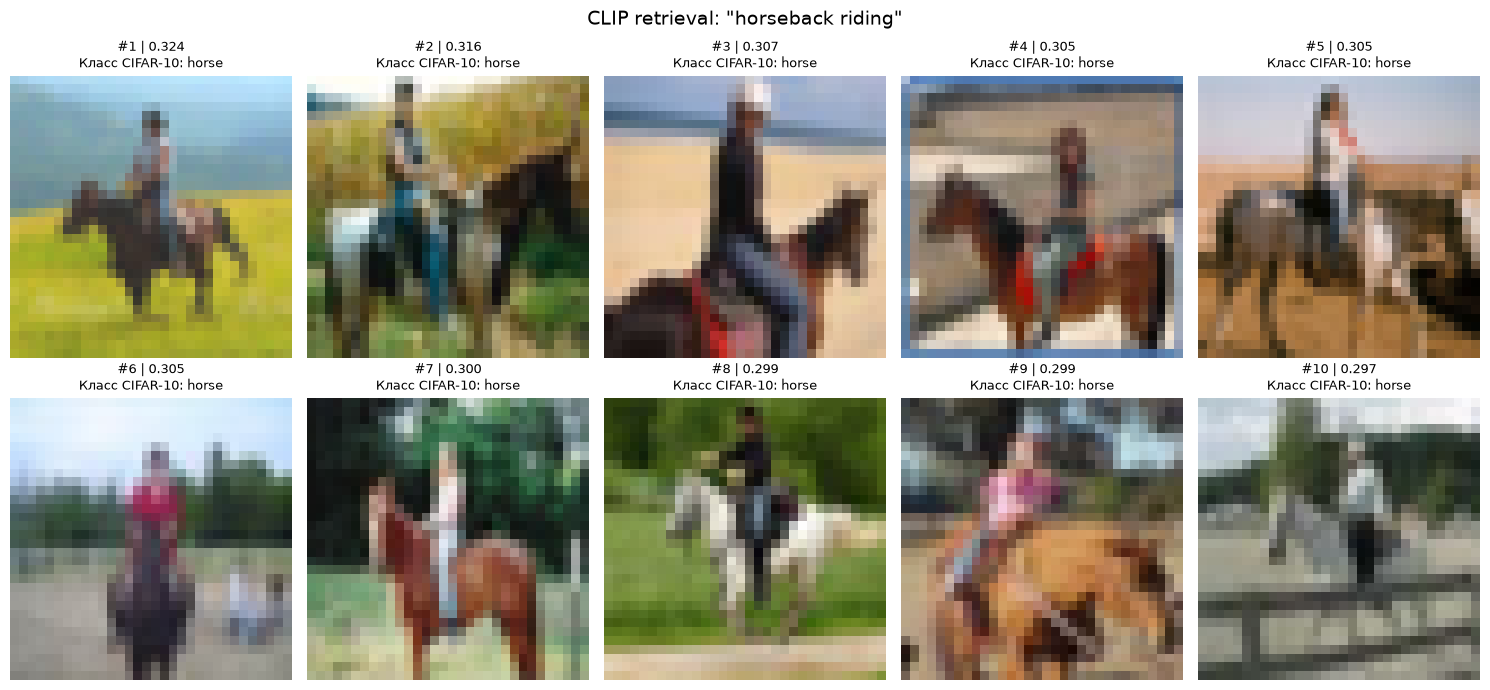

Запрос: horseback riding
Размер поискового индекса: 10000
Найдено изображений: 10
Коллаж: artifacts\bonus_retrieval.png
JSON: artifacts\bonus_query.json


In [27]:
# Композиционный запрос — не название класса CIFAR-10
BONUS_QUERY = "horseback riding"
TOP_K = 10

# Папка с результатами лабораторной
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Загружаем ранее построенный индекс CLIP
index_path = ARTIFACTS / "clip_index.pt"
index_data = torch.load(index_path, map_location="cpu", weights_only=False)

# Эмбеддинги изображений уже нормализованы при построении индекса
image_embeddings = index_data["embeddings"].float()
indexed_labels = index_data["labels"].long()

# Восстанавливаем исходные индексы изображений CIFAR-10
if "indices" in index_data:
    dataset_indices = torch.as_tensor(index_data["indices"]).long()
elif "dataset_indices" in index_data:
    dataset_indices = torch.as_tensor(index_data["dataset_indices"]).long()
elif hasattr(ds, "indices"):
    dataset_indices = torch.as_tensor(ds.indices).long()
else:
    raise KeyError(
        "В индексе нет исходных индексов изображений. "
        "Нужно пересоздать clip_index.pt, сохранив индексы выборки."
    )

# Проверяем согласованность индекса и эмбеддингов
assert len(dataset_indices) == len(image_embeddings), (
    f"Количество индексов ({len(dataset_indices)}) не совпадает "
    f"с количеством эмбеддингов ({len(image_embeddings)})."
)

# Получаем текстовый эмбеддинг запроса
model.eval()
with torch.no_grad():
    tokens = tokenizer([BONUS_QUERY]).to(DEVICE)
    query_embedding = model.encode_text(tokens).float()
    query_embedding = torch.nn.functional.normalize(
        query_embedding, p=2, dim=-1
    ).cpu()

# Поиск по всем изображениям индекса по косинусному сходству
similarities = (image_embeddings @ query_embedding.T).squeeze(1)
k = min(TOP_K, len(similarities))
top_scores, top_positions = torch.topk(similarities, k=k)

# Сохраняем исходные индексы изображений в CIFAR-10,
# а не позиции в отсортированной выдаче
top_dataset_indices = dataset_indices[top_positions].tolist()

results = []
for rank, (position, score, original_idx) in enumerate(
    zip(top_positions.tolist(), top_scores.tolist(), top_dataset_indices),
    start=1
):
    results.append({
        "rank": rank,
        "dataset_index": int(original_idx),
        "similarity": float(score),
        "label_id": int(indexed_labels[position]),
        "class_name": classes[int(indexed_labels[position])]
    })

# Сохраняем запрос и результаты поиска.
# Метки классов — справочная информация о найденных изображениях,
# а не искусственные метки релевантности запросу.
bonus_json_path = ARTIFACTS / "bonus_query.json"
with open(bonus_json_path, "w", encoding="utf-8") as f:
    json.dump({
        "query": BONUS_QUERY,
        "top_k": k,
        "search_space_size": len(image_embeddings),
        "fast_dev_run": FAST_DEV_RUN,
        "results": results
    }, f, ensure_ascii=False, indent=2)

# Строим коллаж top-k
cols = 5
rows = (k + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(15, 3.6 * rows))
axes = np.array(axes).reshape(-1)

for i, (ax, result) in enumerate(zip(axes, results)):
    # CIFAR-10 test dataset возвращает (изображение, метка)
    image, true_label = cifar_test[result["dataset_index"]]

    if isinstance(image, torch.Tensor):
        image = image.detach().cpu()
        if image.ndim == 3 and image.shape[0] in (1, 3):
            image = image.permute(1, 2, 0)
        image = image.numpy()
        if image.min() < 0 or image.max() > 1:
            image = (image - image.min()) / (image.max() - image.min() + 1e-8)
    elif isinstance(image, Image.Image):
        image = np.array(image)

    ax.imshow(image)
    ax.set_title(
        f"#{result['rank']} | {result['similarity']:.3f}\n"
        f"Класс CIFAR-10: {classes[int(true_label)]}",
        fontsize=9
    )
    ax.axis("off")

for ax in axes[k:]:
    ax.axis("off")

fig.suptitle(
    f'CLIP retrieval: "{BONUS_QUERY}"',
    fontsize=14
)
plt.tight_layout()

bonus_png_path = ARTIFACTS / "bonus_retrieval.png"
fig.savefig(bonus_png_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Запрос:", BONUS_QUERY)
print("Размер поискового индекса:", len(image_embeddings))
print("Найдено изображений:", k)
print("Коллаж:", bonus_png_path)
print("JSON:", bonus_json_path)

## Анализ результатов

В ходе лабораторной работы я проверил работу CLIP на тестовой выборке CIFAR-10. Сравнил точность определения классов до и после адаптации модели, а также качество поиска изображений по текстовому запросу.

До адаптации точность классификации составила 0.937, после — 0.964. Показатель Precision@10 составил 1 до адаптации и 1 после неё. Можно сделать вывод, что если в текстовом запросе содержится название класса, модель с уверенностью находит 10 верных изображений этого класса

В качестве бюджета использовались 20000 обучающих изображений, 3000 проверочных и 10000 тестовых.

Среди 10 ближайших векторных представлений текстового запроса для всех классов не удалось обнаружить ошибку. 

Творческий бонус также дает понять, что модель учитывает не только объект на изображении, но также и окружающую среду.
